<a href="https://colab.research.google.com/github/strangestmahi/statistical-foundation-of-data-science/blob/main/Practical1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# I imported the three libraries.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pyplot

# I loaded the Student Rating dataset from a CSV file using Pandas. The head() function displays the first five rows so that I can check the data.

In [ ]:
ratings_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/teachingratings.csv"

ratings_df = pd.read_csv(ratings_url)

ratings_df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1


# First, I selected only the professors who are visible minorities. Then I checked how many of these professors are tenured. Finally, I multiplied the result by 100 to get the percentage.

In [ ]:
minority_professors = ratings_df[ratings_df["minority"] == "yes"]

percentage_tenured = (
    (minority_professors["tenure"] == "yes").mean() * 100
)

print("Percentage of visible minorities who are tenured:",
      round(percentage_tenured, 2), "%")

Percentage of visible minorities who are tenured: 84.38 %


# I used cross-tabulation to compare minority status and tenure status. normalize="index" converts the counts into percentages for each minority group.

In [ ]:
tenure_by_minority = pd.crosstab(
    ratings_df["minority"],
    ratings_df["tenure"],
    normalize="index"
) * 100

print(tenure_by_minority.round(2))

tenure       no    yes
minority              
no        23.06  76.94
yes       15.62  84.38


# grouped the professors according to their tenure status. Then I calculated the mean age and standard deviation for each group.

In [ ]:
age_by_tenure = ratings_df.groupby("tenure")["age"].agg(["mean", "std"])

print(age_by_tenure.round(2))

         mean    std
tenure              
no      50.19   6.95
yes     47.85  10.42


# Age is a numerical variable, so a histogram is suitable. The histogram shows how many professors fall into different age ranges.

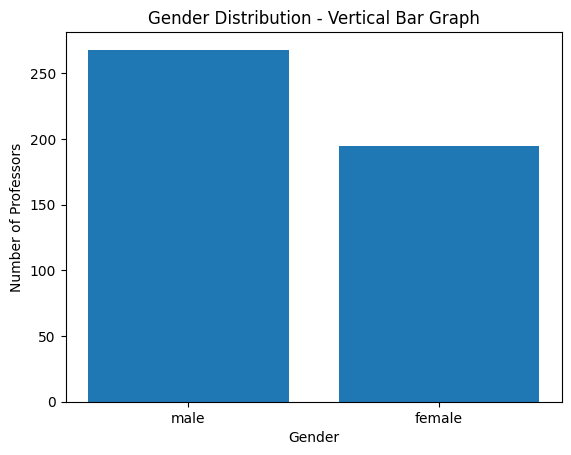

In [ ]:
pyplot.hist(ratings_df["age"], bins=10, edgecolor="black")

pyplot.xlabel("Age")
pyplot.ylabel("Frequency")
pyplot.title("Distribution of Professor Age")

pyplot.show()

# pyplot.barh() creates a horizontal bar graph. The gender categories are shown on the Y-axis and the number of professors is shown on the X-axis.

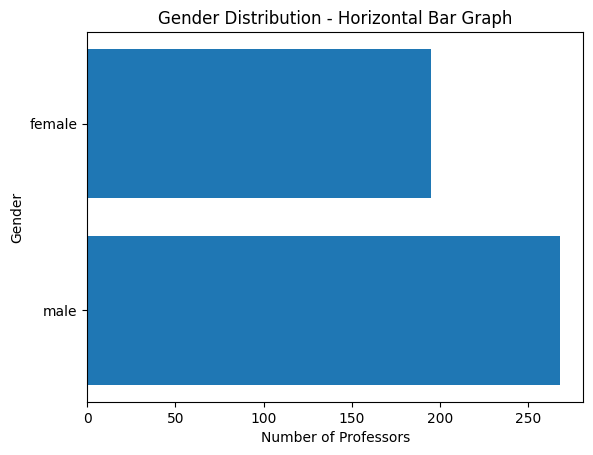

In [ ]:
gender_count = ratings_df["gender"].value_counts()

pyplot.barh(gender_count.index, gender_count.values)

pyplot.xlabel("Number of Professors")
pyplot.ylabel("Gender")
pyplot.title("Gender Distribution - Horizontal Bar Graph")

pyplot.show()

# pyplot.bar() creates a vertical bar graph, while pyplot.barh() creates a horizontal bar graph.

In [ ]:
print("pyplot.bar() creates vertical bars.")
print("pyplot.barh() creates horizontal bars.")

pyplot.bar() creates vertical bars.
pyplot.barh() creates horizontal bars.


# Gender is a categorical variable, so I used a bar graph. value_counts() counts the number of professors in each gender category. The bar graph then displays these counts.

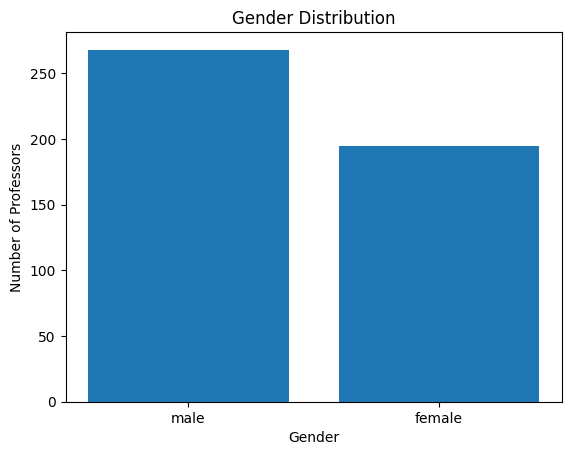

In [ ]:
gender_count = ratings_df["gender"].value_counts()

pyplot.bar(gender_count.index, gender_count.values)

pyplot.xlabel("Gender")
pyplot.ylabel("Number of Professors")
pyplot.title("Gender Distribution")

pyplot.show()

# First, I selected only the professors who are tenured. Then I selected their evaluation scores and calculated the median using the median() function.

In [ ]:
tenured_professors = ratings_df[ratings_df["tenure"] == "yes"]

median_eval = tenured_professors["eval"].median()

print("Median evaluation score for tenured professors:",
      median_eval)

Median evaluation score for tenured professors: 4.0
